# 02 – Distributions and Outliers

**Objective:** analyse the distribution of the target (`PRICE`) and of the main numerical, categorical and binary features, detect outliers and erroneous extreme values, and decide how to treat them before modelling.

**Input:** `data/processed/listings_01.parquet` (output of notebook 01).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# Consistent visual style
sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

PERIOD_MAP = {"201803": "Q1 2018", "201806": "Q2 2018", "201809": "Q3 2018", "201812": "Q4 2018"}

df = pd.read_parquet("../data/processed/listings_01.parquet")

print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")

Loaded: 75,795 rows × 39 columns


In [2]:
main_num_cols = ["PRICE", "CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER",
                 "FLOORCLEAN", "CADCONSTRUCTIONYEAR", "CADMAXBUILDINGFLOOR",
                 "CADDWELLINGCOUNT", "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO"]

df[main_num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
PRICE,75795.0,389080.183389,412459.348500,21000.000000,157000.000000,257000.000000,457000.000000,8.133000e+06
CONSTRUCTEDAREA,75795.0,100.255386,66.470333,21.000000,62.000000,82.000000,115.000000,9.850000e+02
ROOMNUMBER,75795.0,2.569272,1.198722,0.000000,2.000000,3.000000,3.000000,2.000000e+01
BATHNUMBER,75795.0,1.570816,0.836367,0.000000,1.000000,1.000000,2.000000,2.000000e+01
FLOORCLEAN,75795.0,2.714467,2.211543,-1.000000,1.000000,2.000000,4.000000,1.100000e+01
CADCONSTRUCTIONYEAR,75795.0,1965.465400,28.920675,1623.000000,1955.000000,1967.000000,1983.000000,2.018000e+03
CADMAXBUILDINGFLOOR,75795.0,6.360868,2.842924,0.000000,5.000000,6.000000,8.000000,2.600000e+01
CADDWELLINGCOUNT,75795.0,38.714387,53.303842,1.000000,12.000000,21.000000,39.000000,1.499000e+03
DISTANCE_TO_CITY_CENTER,75795.0,4.476765,2.671411,0.015374,2.403508,4.114314,6.219253,1.415881e+01
DISTANCE_TO_METRO,75795.0,0.470128,0.595199,0.001416,0.212755,0.330032,0.519243,9.344541e+00


## 1. Target variable: `PRICE`

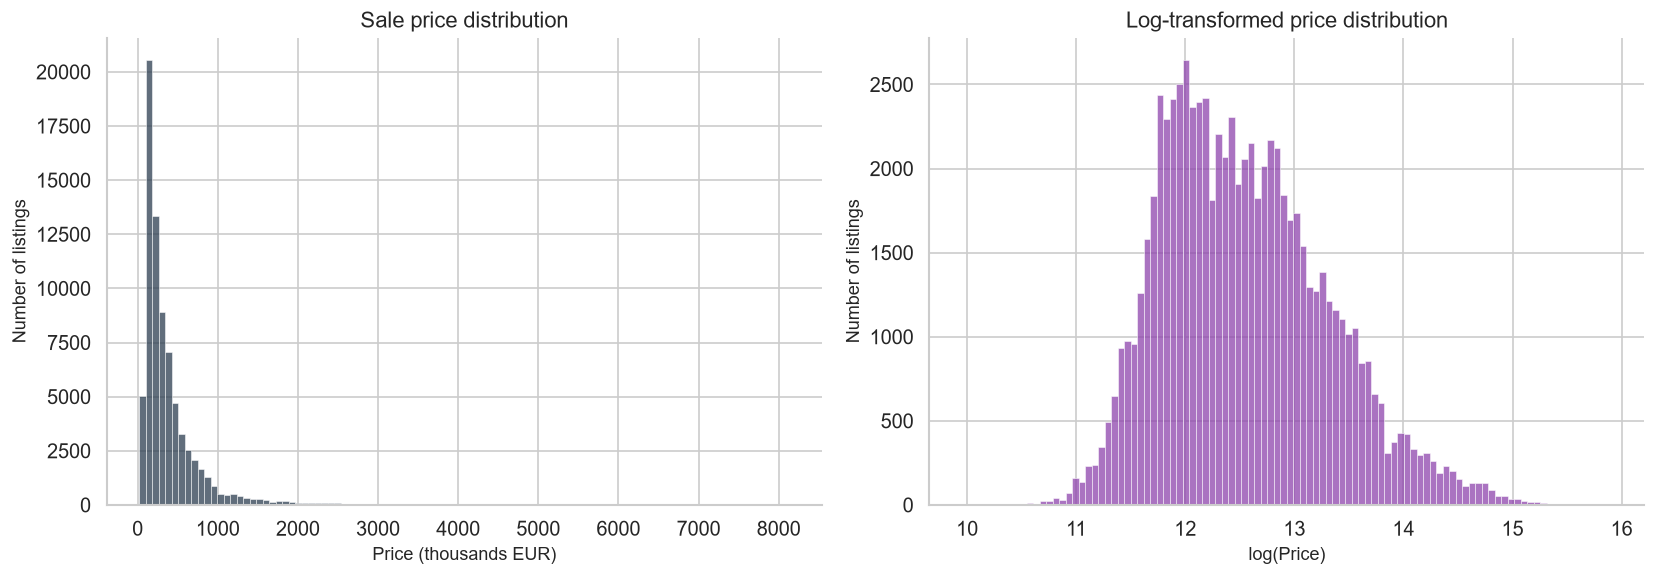

Skewness PRICE:      4.07
Skewness log(PRICE): 0.54


In [3]:
price = df["PRICE"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(price / 1000, bins=100, ax=axes[0], color="#2c3e50", edgecolor="white", linewidth=0.3)
axes[0].set_xlabel("Price (thousands EUR)")
axes[0].set_ylabel("Number of listings")
axes[0].set_title("Sale price distribution")

sns.histplot(np.log(price), bins=100, ax=axes[1], color="#8e44ad", edgecolor="white", linewidth=0.3)
axes[1].set_xlabel("log(Price)")
axes[1].set_ylabel("Number of listings")
axes[1].set_title("Log-transformed price distribution")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

print(f"Skewness PRICE:      {price.skew():.2f}")
print(f"Skewness log(PRICE): {np.log(price).skew():.2f}")

The raw sale price is strongly right-skewed: most properties are priced below 500,000 EUR, but a few reach several million. After a log transformation the distribution becomes approximately symmetric. **Conclusion:** the model should predict `log(PRICE)` instead of `PRICE`, and outliers should be evaluated on the log scale.

In [4]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

low, high = iqr_bounds(price)
n_out = ((price < low) | (price > high)).sum()
print(f"IQR on PRICE:      [{low:,.0f}, {high:,.0f}] EUR  -> {n_out:,} outliers ({n_out/len(price):.1%})")

log_price = np.log(price)
log_low, log_high = iqr_bounds(log_price)
n_out_log = ((log_price < log_low) | (log_price > log_high)).sum()
print(f"IQR on log(PRICE): [{np.exp(log_low):,.0f}, {np.exp(log_high):,.0f}] EUR  -> {n_out_log:,} outliers ({n_out_log/len(price):.1%})")

IQR on PRICE:      [-293,000, 907,000] EUR  -> 5,494 outliers (7.2%)
IQR on log(PRICE): [31,614, 2,269,557] EUR  -> 679 outliers (0.9%)


Extreme-outlier fence (3·IQR on log scale): [6,366, 11,271,088] EUR
Listings outside the fence: 0



Price per m² in the original file: 805 – 9,998 EUR/m²
Price per m² after notebook 01:    805 – 9,998 EUR/m²


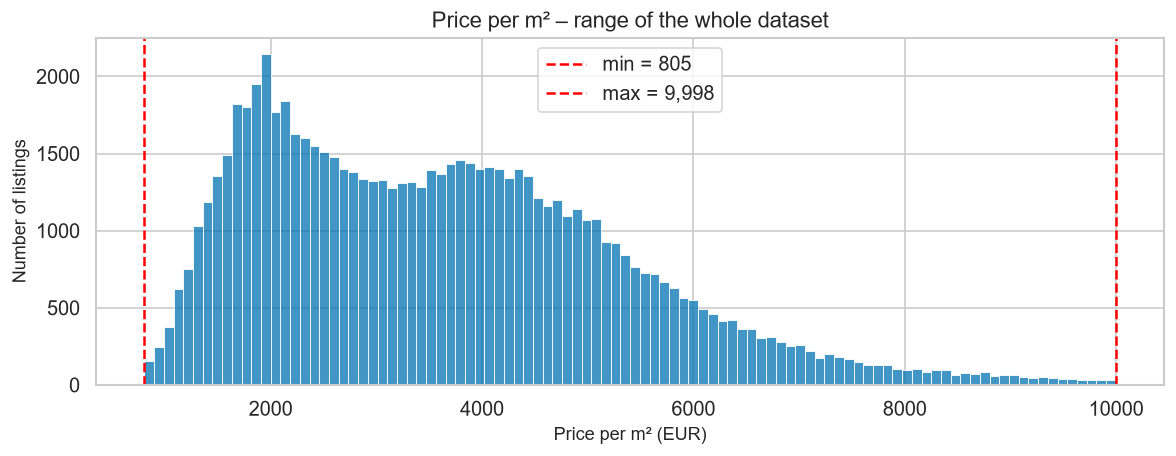

In [5]:
log_low3, log_high3 = iqr_bounds(log_price, k=3)
print(f"Extreme-outlier fence (3·IQR on log scale): [{np.exp(log_low3):,.0f}, {np.exp(log_high3):,.0f}] EUR")
print(f"Listings outside the fence: {((log_price < log_low3) | (log_price > log_high3)).sum()}")

price_m2 = df["PRICE"] / df["CONSTRUCTEDAREA"]
raw = pd.read_csv("../data/Madrid_Sale.csv", usecols=["UNITPRICE"])
print(f"\nPrice per m² in the original file: {raw['UNITPRICE'].min():,.0f} – {raw['UNITPRICE'].max():,.0f} EUR/m²")
print(f"Price per m² after notebook 01:    {price_m2.min():,.0f} – {price_m2.max():,.0f} EUR/m²")

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(price_m2, bins=100, ax=ax)
ax.axvline(price_m2.min(), color="red", linestyle="--", label=f"min = {price_m2.min():,.0f}")
ax.axvline(price_m2.max(), color="red", linestyle="--", label=f"max = {price_m2.max():,.0f}")
ax.set_xlabel("Price per m² (EUR)")
ax.set_ylabel("Number of listings")
ax.set_title("Price per m² – range of the whole dataset")
ax.legend()
plt.tight_layout()
plt.show()

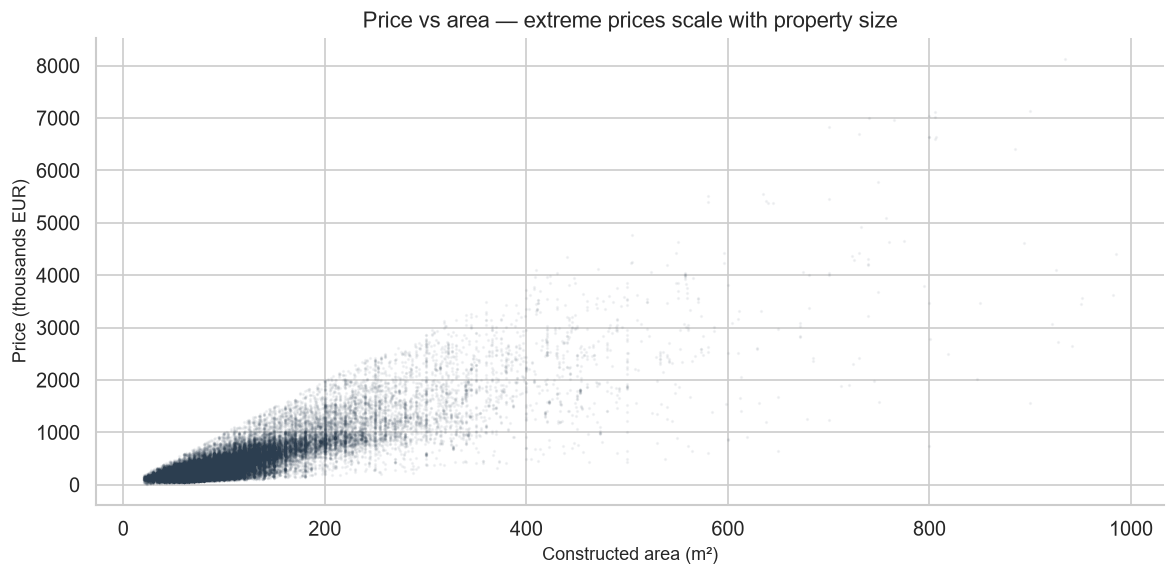

Median EUR/m² (all): 3,444


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(df["CONSTRUCTEDAREA"], df["PRICE"] / 1000, alpha=0.05, s=1, color="#2c3e50")
ax.set_xlabel("Constructed area (m²)")
ax.set_ylabel("Price (thousands EUR)")
ax.set_title("Price vs area — extreme prices scale with property size")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"Median EUR/m² (all): {(df['PRICE'] / df['CONSTRUCTEDAREA']).median():,.0f}")

### Decision on price outliers

- **No extreme outliers exist.** The extreme-outlier fence (Q3 + 3·IQR on the log scale) is 6,366 – 11.3 M€, and no listing falls outside it.
- **The dataset appears to be pre-filtered by its authors.** The price per m² of every listing lies between 805 and 9,998 €/m², both in the original file and after notebook 01. The abrupt start of the distribution and a maximum just below 10,000 €/m² suggest that listings with implausible unit prices were removed before publication. This explains why there are no placeholder or absurd prices.
- **Moderate outliers are kept.** The 1.5·IQR rule on the log scale flags 679 listings (0.9%) outside 31,614 – 2.27 M€. The price vs area plot shows that the most expensive listings are also the largest ones: they are real luxury properties, not errors. Modelling `log(PRICE)` will limit their influence.
- Applying the IQR rule to the raw price is not appropriate: it flags 7.2% of listings and gives a negative lower bound (−293,000 €).

**Action:** no listings are removed in this section.

## 2. Main numerical features

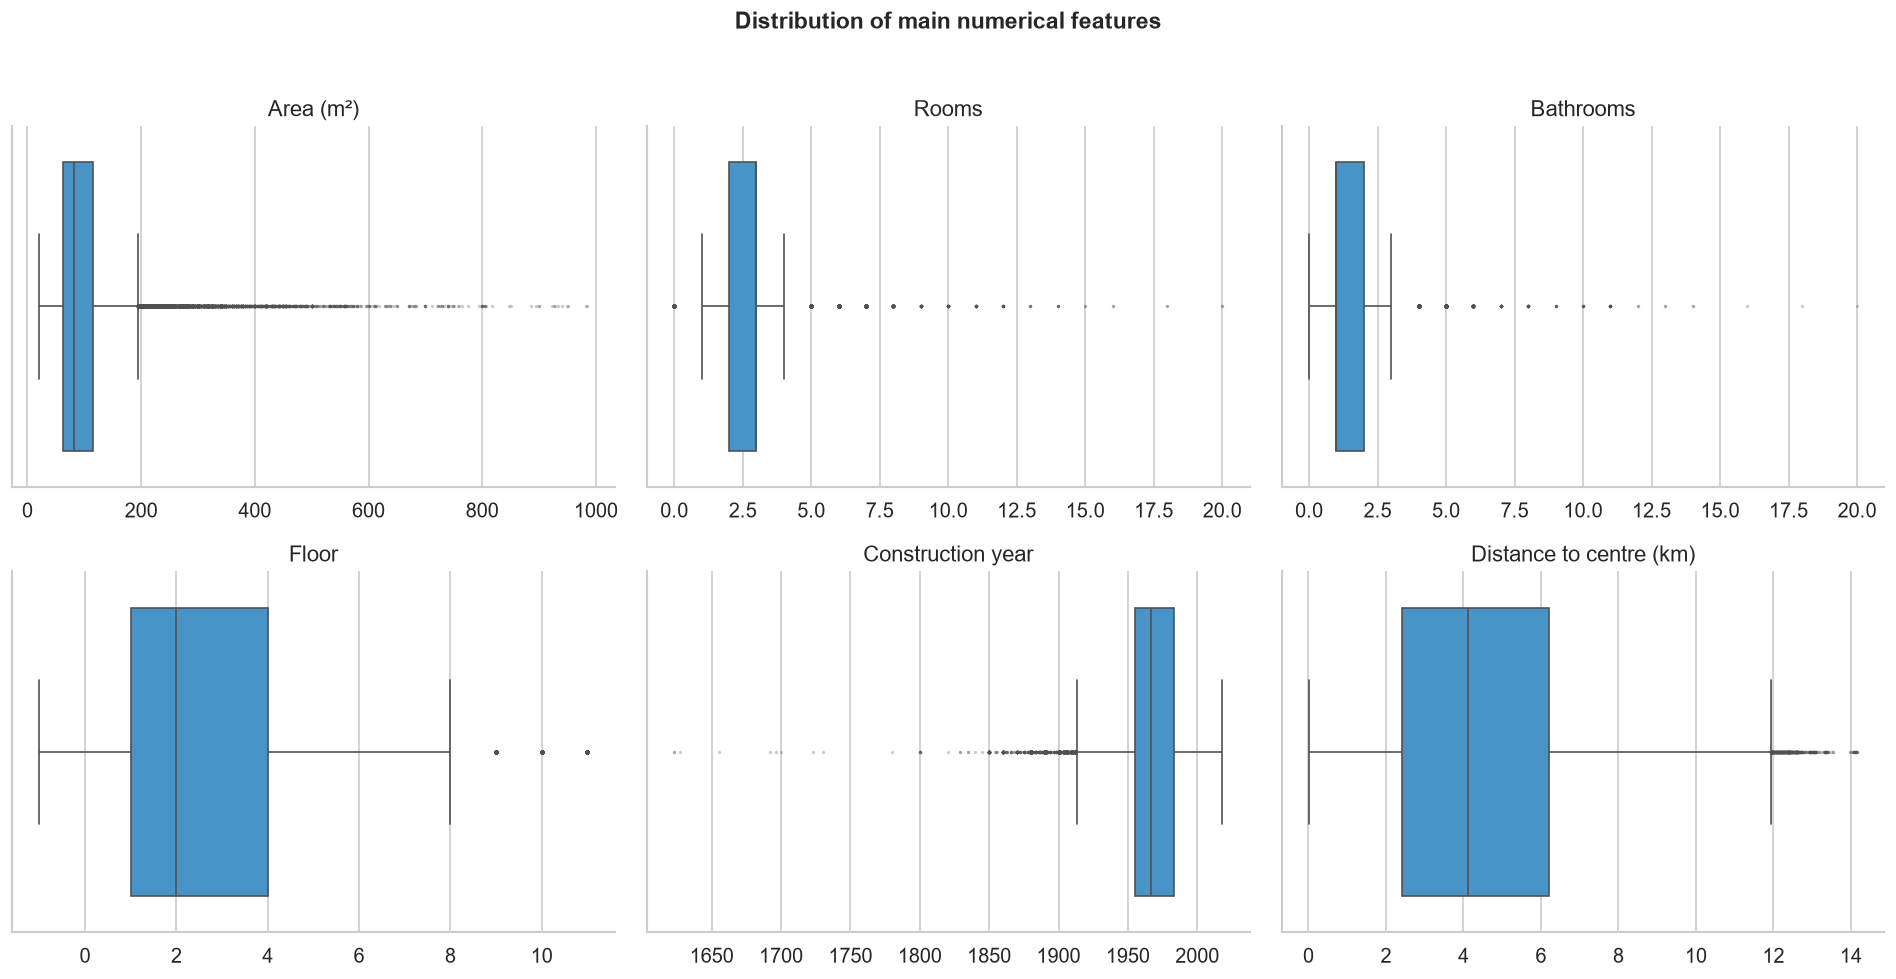

In [7]:
feat_cols = ["CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER", "FLOORCLEAN",
             "CADCONSTRUCTIONYEAR", "DISTANCE_TO_CITY_CENTER"]

readable_names = {
    "CONSTRUCTEDAREA": "Area (m²)",
    "ROOMNUMBER": "Rooms",
    "BATHNUMBER": "Bathrooms",
    "FLOORCLEAN": "Floor",
    "CADCONSTRUCTIONYEAR": "Construction year",
    "DISTANCE_TO_CITY_CENTER": "Distance to centre (km)"
}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), feat_cols):
    sns.boxplot(x=df[col], ax=ax, color="#3498db", flierprops=dict(marker=".", markersize=2, alpha=0.3))
    ax.set_title(readable_names.get(col, col))
    ax.set_xlabel("")
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Distribution of main numerical features", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Investigating extreme values before treating them

Before applying any treatment, we inspect which listings would be affected by each candidate rule.

Listings with CONSTRUCTEDAREA > 500 m²: 189
       CONSTRUCTEDAREA  ROOMNUMBER  BATHNUMBER         PRICE  \
count       189.000000  189.000000  189.000000  1.890000e+02   
mean        636.417989    5.925926    4.708995  3.254786e+06   
std         119.578826    3.199869    2.640715  1.545367e+06   
min         501.000000    0.000000    1.000000  4.880000e+05   
25%         548.000000    5.000000    3.000000  2.349000e+06   
50%         580.000000    6.000000    4.000000  3.039000e+06   
75%         720.000000    7.000000    6.000000  4.024000e+06   
max         985.000000   20.000000   20.000000  8.133000e+06   

       DISTANCE_TO_CITY_CENTER  
count               189.000000  
mean                  3.017960  
std                   2.003907  
min                   0.083329  
25%                   1.710670  
50%                   2.489297  
75%                   3.908721  
max                  10.908814  


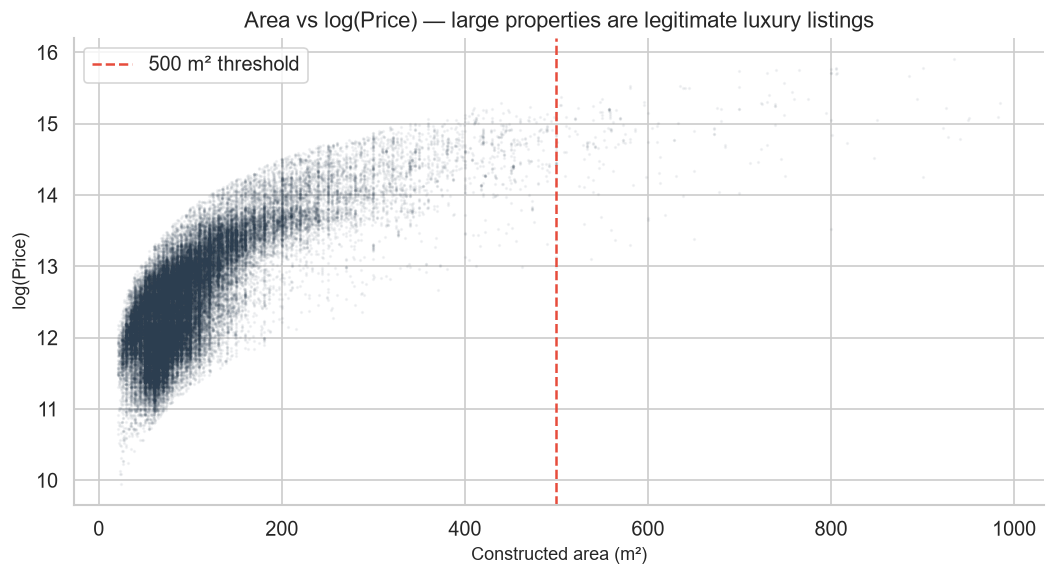

In [8]:
large = df[df["CONSTRUCTEDAREA"] > 500]
print(f"Listings with CONSTRUCTEDAREA > 500 m²: {len(large)}")
print(large[["CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER", "PRICE", "DISTANCE_TO_CITY_CENTER"]].describe())

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df["CONSTRUCTEDAREA"], np.log(df["PRICE"]), alpha=0.05, s=1, color="#2c3e50")
ax.axvline(500, color="#e74c3c", linestyle="--", lw=1.5, label="500 m² threshold")
ax.set_xlabel("Constructed area (m²)")
ax.set_ylabel("log(Price)")
ax.set_title("Area vs log(Price) — large properties are legitimate luxury listings")
ax.legend(frameon=True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

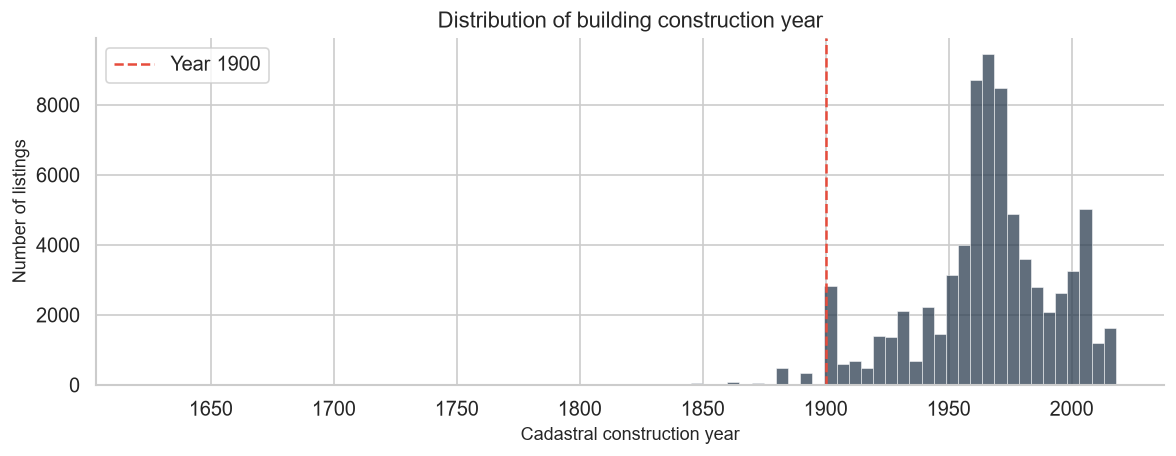

Buildings before 1900: 1095 (1.4%)
Median price (pre-1900): 358,000 EUR
Median price (1900+):    255,000 EUR


In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(df["CADCONSTRUCTIONYEAR"], bins=80, ax=ax, color="#2c3e50", edgecolor="white", linewidth=0.3)
ax.axvline(1900, color="#e74c3c", linestyle="--", lw=1.5, label="Year 1900")
ax.set_xlabel("Cadastral construction year")
ax.set_ylabel("Number of listings")
ax.set_title("Distribution of building construction year")
ax.legend(frameon=True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

old = df[df["CADCONSTRUCTIONYEAR"] < 1900]
print(f"Buildings before 1900: {len(old)} ({len(old)/len(df):.1%})")
print(f"Median price (pre-1900): {old['PRICE'].median():,.0f} EUR")
print(f"Median price (1900+):    {df[df['CADCONSTRUCTIONYEAR'] >= 1900]['PRICE'].median():,.0f} EUR")

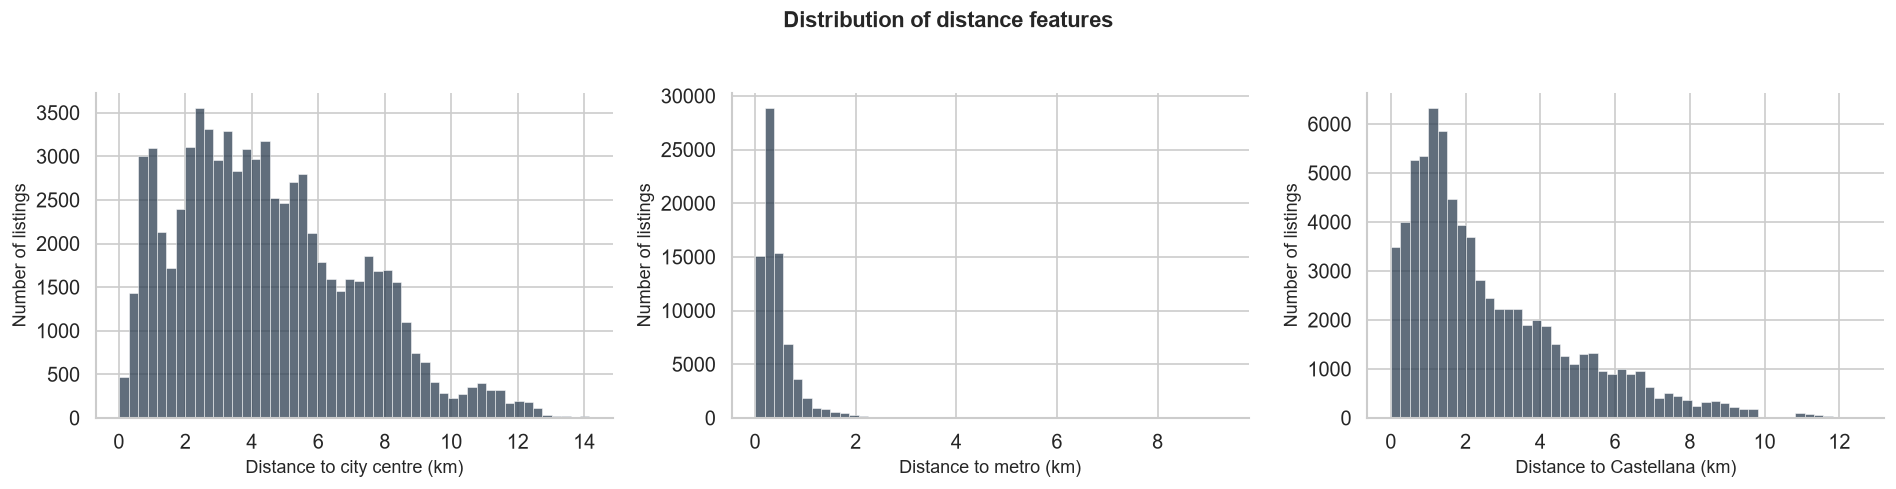

CADDWELLINGCOUNT > 500: 78 listings
       CADDWELLINGCOUNT  CADMAXBUILDINGFLOOR         PRICE
count         78.000000            78.000000  7.800000e+01
mean         607.474359             9.653846  5.946346e+05
std          130.127482             2.931366  2.104917e+05
min          501.000000             5.000000  7.500000e+04
25%          532.000000             8.000000  4.620000e+05
50%          574.000000             9.000000  5.640000e+05
75%          685.250000            14.000000  7.227500e+05
max         1499.000000            14.000000  1.372000e+06


In [10]:
dist_cols = ["DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO", "DISTANCE_TO_CASTELLANA"]
dist_labels = ["Distance to city centre (km)", "Distance to metro (km)", "Distance to Castellana (km)"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, label in zip(axes, dist_cols, dist_labels):
    sns.histplot(df[col], bins=50, ax=ax, color="#2c3e50", edgecolor="white", linewidth=0.3)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of listings")
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Distribution of distance features", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print(f"CADDWELLINGCOUNT > 500: {(df['CADDWELLINGCOUNT'] > 500).sum()} listings")
print(df[df["CADDWELLINGCOUNT"] > 500][["CADDWELLINGCOUNT", "CADMAXBUILDINGFLOOR", "PRICE"]].describe())

### Decisions on feature outliers

Each extreme value was inspected before deciding on a treatment:

- **`CONSTRUCTEDAREA` > 500 m² (189 listings):** legitimate large properties. Their price scales with area (see the area vs log(price) plot). **Action:** kept, they represent the luxury segment.
- **`CADCONSTRUCTIONYEAR` < 1900 (1,095 listings, 1.4%):** historic buildings with a *higher* median price (358,000 €) than newer ones (255,000 €). **Action:** kept, they are real and informative.
- **Distance features:** smooth distributions with no suspicious spikes or gaps. **Action:** kept as they are.
- **`CADDWELLINGCOUNT` > 500 (78 listings):** large residential complexes, with plausible building heights and prices. **Action:** kept.
- **No capping at the 99th percentile.** All features describe the property being sold, and the extreme values inspected are consistent with each other (large area, many rooms, high price), so they reflect the real market.

## 3. Categorical features

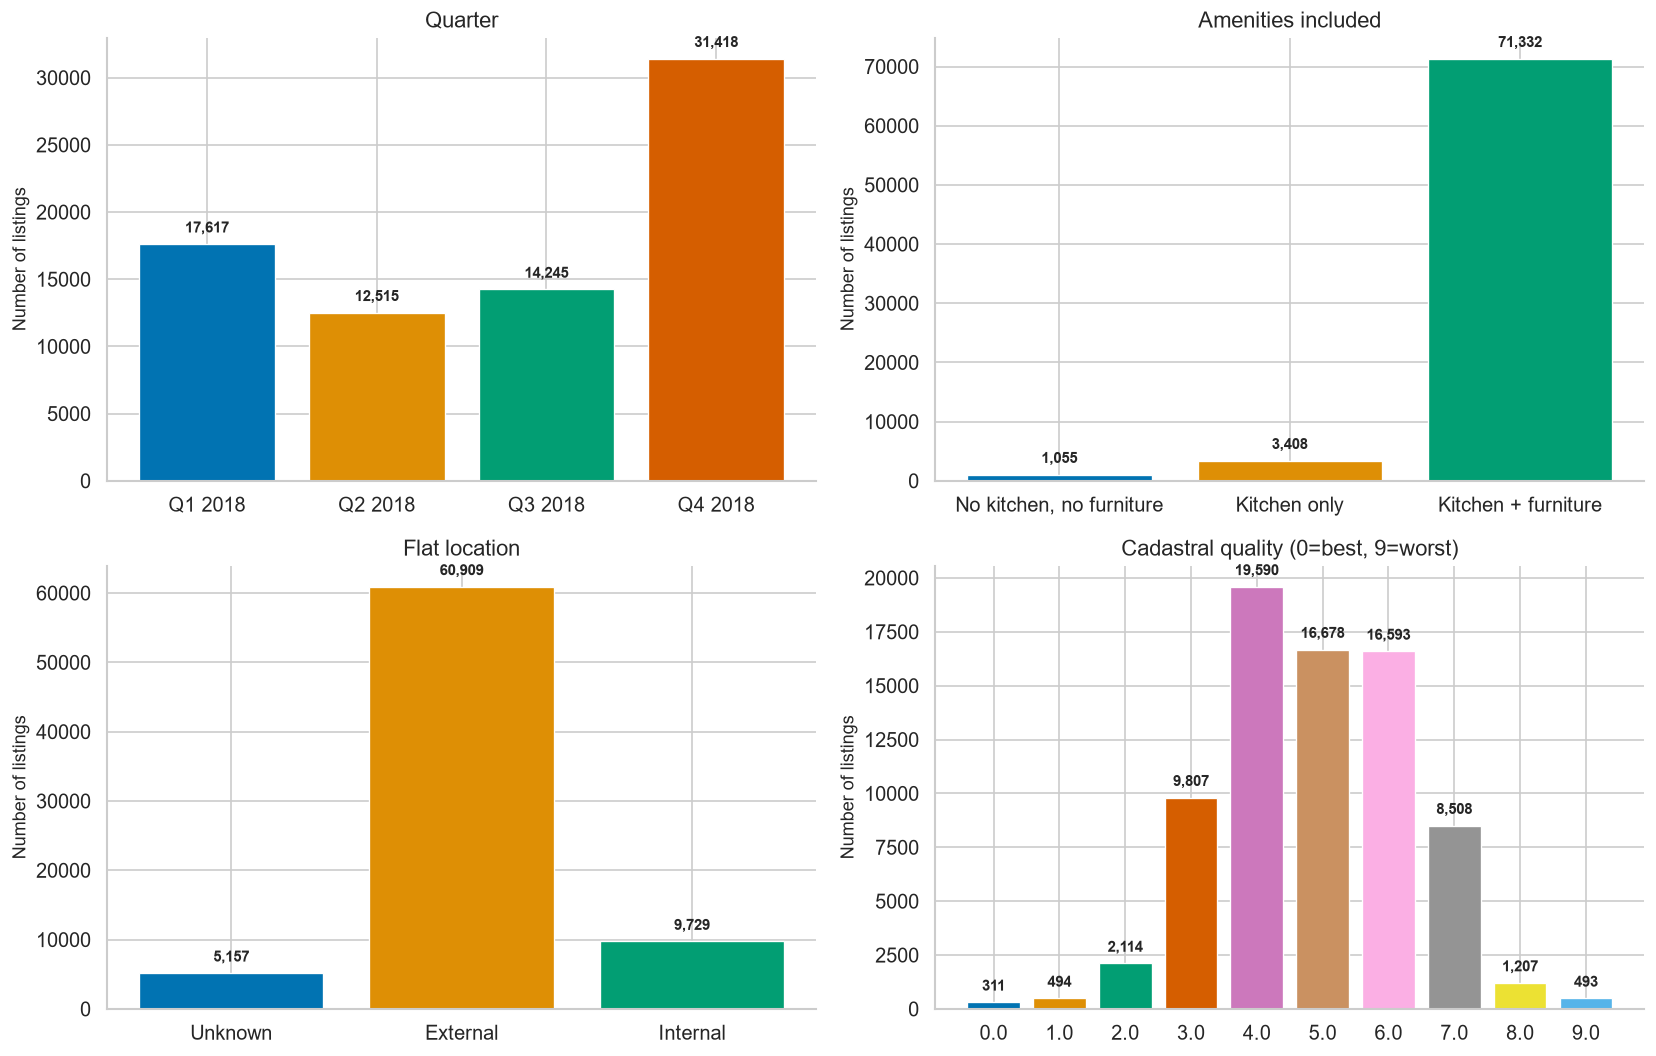


PERIOD:
PERIOD
201803    0.232
201806    0.165
201809    0.188
201812    0.415
Name: proportion, dtype: float64

AMENITYID:
AMENITYID
1    0.014
2    0.045
3    0.941
Name: proportion, dtype: float64

FLATLOCATIONID:
FLATLOCATIONID
0    0.068
1    0.804
2    0.128
Name: proportion, dtype: float64

CADASTRALQUALITYID:
CADASTRALQUALITYID
0.0    0.004
1.0    0.007
2.0    0.028
3.0    0.129
4.0    0.258
5.0    0.220
6.0    0.219
7.0    0.112
8.0    0.016
9.0    0.007
Name: proportion, dtype: float64


In [11]:
cat_cols = ["PERIOD", "AMENITYID", "FLATLOCATIONID", "CADASTRALQUALITYID"]

cat_labels = {
    "PERIOD": "Quarter",
    "AMENITYID": "Amenities included",
    "FLATLOCATIONID": "Flat location",
    "CADASTRALQUALITYID": "Cadastral quality (0=best, 9=worst)"
}

# Human-readable tick labels (from the official idealista18 documentation)
tick_maps = {
    "PERIOD": PERIOD_MAP,
    "FLATLOCATIONID": {0: "Unknown", 1: "External", 2: "Internal"},
    "AMENITYID": {1: "No kitchen, no furniture", 2: "Kitchen only", 3: "Kitchen + furniture"},
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
palette = sns.color_palette("colorblind")

for ax, col in zip(axes.ravel(), cat_cols):
    counts = df[col].value_counts().sort_index()
    tick_map = tick_maps.get(col, {})
    labels = [tick_map.get(v, str(v)) for v in counts.index]

    bars = ax.bar(labels, counts.values, color=palette[:len(counts)], edgecolor="white", linewidth=0.8)
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + counts.max() * 0.02,
                f"{val:,}", ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_title(cat_labels.get(col, col))
    ax.set_ylabel("Number of listings")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(normalize=True).sort_index().round(3))

In [12]:
quality_price = df.groupby("CADASTRALQUALITYID")["PRICE"].agg(["count", "median"])
quality_price["median"] = quality_price["median"].round(0)
quality_price

,count,median
CADASTRALQUALITYID,,
0.0,311,859000.0
1.0,494,1061000.0
2.0,2114,747000.0
3.0,9807,504000.0
4.0,19590,354000.0
5.0,16678,265000.0
6.0,16593,160000.0
7.0,8508,138000.0
8.0,1207,175000.0


### Findings on categorical features

- **`PERIOD` is not balanced:** Q4 2018 has 31,418 listings (41.5%), while the other quarters have between 12,515 (16.5%) and 17,617 (23.2%). This was already observed in notebook 00 and may reflect a change in data collection. The quarter should be included in the model so that it can capture any time effect.
- **`AMENITYID`** (amenities included, according to the official documentation): 94.1% of listings include kitchen and furniture (3), 4.5% only kitchen (2) and 1.4% neither (1). The variable is very unbalanced, so its predictive power may be limited.
- **`FLATLOCATIONID`:** 80.4% external views (1), 12.8% internal (2) and 6.8% unknown (0, imputed in notebook 01).
- **`CADASTRALQUALITYID`:** 10 levels, with 69.7% of listings in levels 4–6. The table above shows that the median price falls from 1.06 M€ (level 1) to 138,000 € (level 7), which confirms that **lower values mean higher quality**. Levels 0, 8 and 9 are rare (< 1.7% each), so their medians are less reliable.

**No action needed:** all values are valid. The imbalance of `PERIOD` and `AMENITYID` is noted for the modelling stage.

## 4. Binary features distribution

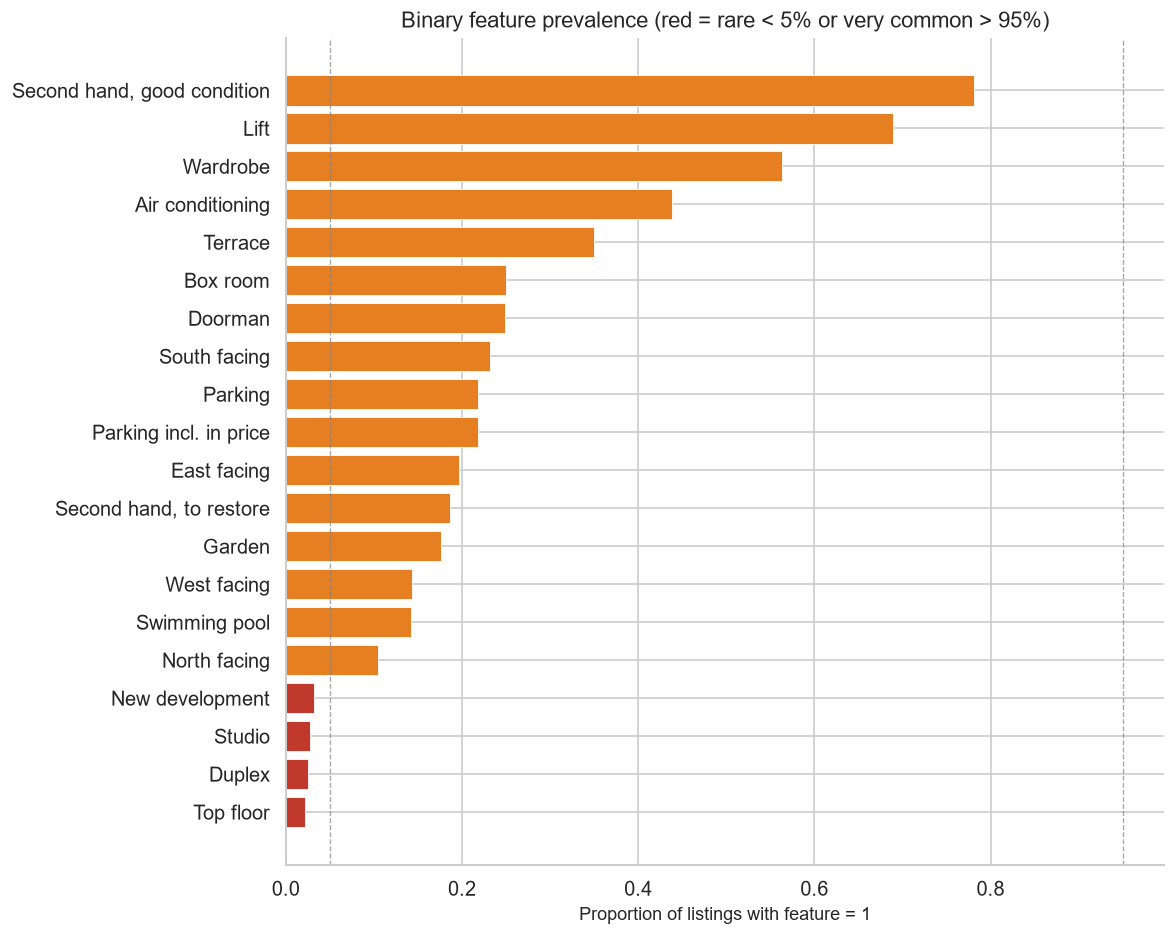

Rare features (< 5%):
ISINTOPFLOOR     0.022
ISDUPLEX         0.025
ISSTUDIO         0.027
BUILTTYPEID_1    0.032
dtype: float64

Very common features (> 95%):
Series([], dtype: float64)


In [13]:
binary_cols = [c for c in df.columns if c.startswith("HAS") or c.startswith("IS") or c.startswith("BUILTTYPEID")]

proportions = df[binary_cols].mean().sort_values(ascending=True)

# Readable names
readable = {
    "HASTERRACE": "Terrace", "HASLIFT": "Lift", "HASAIRCONDITIONING": "Air conditioning",
    "HASPARKINGSPACE": "Parking", "ISPARKINGSPACEINCLUDEDINPRICE": "Parking incl. in price",
    "HASNORTHORIENTATION": "North facing", "HASSOUTHORIENTATION": "South facing",
    "HASEASTORIENTATION": "East facing", "HASWESTORIENTATION": "West facing",
    "HASBOXROOM": "Box room", "HASWARDROBE": "Wardrobe", "HASSWIMMINGPOOL": "Swimming pool",
    "HASDOORMAN": "Doorman", "HASGARDEN": "Garden", "ISDUPLEX": "Duplex",
    "ISSTUDIO": "Studio", "ISINTOPFLOOR": "Top floor",
    "BUILTTYPEID_1": "New development", "BUILTTYPEID_2": "Second hand, to restore", "BUILTTYPEID_3": "Second hand, good condition",
    }
labels = [readable.get(c, c) for c in proportions.index]

fig, ax = plt.subplots(figsize=(10, 8))
colors = ["#e67e22" if 0.05 < v < 0.95 else "#c0392c" for v in proportions]
ax.barh(labels, proportions.values, color=colors, edgecolor="white", linewidth=0.5)
ax.set_xlabel("Proportion of listings with feature = 1")
ax.set_title("Binary feature prevalence (red = rare < 5% or very common > 95%)")
ax.axvline(0.05, color="gray", linestyle="--", lw=0.8, alpha=0.7)
ax.axvline(0.95, color="gray", linestyle="--", lw=0.8, alpha=0.7)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print("Rare features (< 5%):")
print(proportions[proportions < 0.05].round(3))
print("\nVery common features (> 95%):")
print(proportions[proportions > 0.95].round(3))

In [14]:
same = (df["HASPARKINGSPACE"] == df["ISPARKINGSPACEINCLUDEDINPRICE"]).mean()
print(f"HASPARKINGSPACE == ISPARKINGSPACEINCLUDEDINPRICE in {same:.1%} of listings")

built_cols = ["BUILTTYPEID_1", "BUILTTYPEID_2", "BUILTTYPEID_3"]
print(f"\nNumber of BUILTTYPEID flags per listing: {df[built_cols].sum(axis=1).value_counts().to_dict()}")

orient_cols = ["HASNORTHORIENTATION", "HASSOUTHORIENTATION", "HASEASTORIENTATION", "HASWESTORIENTATION"]
n_orient = df[orient_cols].sum(axis=1)
print(f"Listings with no orientation reported: {(n_orient == 0).mean():.1%}")
print(f"Listings with 2 or more orientations:  {(n_orient >= 2).mean():.1%}")

HASPARKINGSPACE == ISPARKINGSPACEINCLUDEDINPRICE in 100.0% of listings

Number of BUILTTYPEID flags per listing: {1: 75795}
Listings with no orientation reported: 53.1%
Listings with 2 or more orientations:  17.9%


### Findings on binary features

- **Rare features (< 5%):** top floor (2.2%), duplex (2.5%), studio (2.7%) and new development (3.2%). They are kept: even rare features can be very informative for the price when present.
- **No feature is almost constant (> 95%).** The most common one is "second hand, good condition" (78.1%).
- **`HASPARKINGSPACE` and `ISPARKINGSPACEINCLUDEDINPRICE` are identical in 100% of listings**, so one of them is redundant.
- **`BUILTTYPEID_1/2/3` are a single categorical variable** (condition of the property: new development, second hand to restore, second hand in good condition) split into three columns: every listing has exactly one of them set to 1. For linear models one of them must be left out to avoid perfect collinearity.
- **Orientations are not mutually exclusive** (as stated in the official documentation): 17.9% of listings report two or more, and 53.1% report none. A value of 0 therefore often means "not reported" rather than "not facing that direction".

**Action:** drop `ISPARKINGSPACEINCLUDEDINPRICE`. The rest of the binary features are kept.

## Summary and next steps

**Actions performed in this notebook** (input: 75,795 properties × 39 columns from notebook 01)

| Issue | Evidence | Action |
|---|---|---|
| `PRICE` strongly right-skewed | Skewness 4.07 → 0.54 after log transformation | Model `log(PRICE)` |
| Extreme price outliers | No listing outside the 3·IQR fence on the log scale; price per m² between 805 and 9,998 € in the whole dataset (pre-filtered by the source) | None removed |
| Moderate price outliers (679, 0.9%) | The most expensive listings are also the largest: real luxury properties | Kept |
| `CONSTRUCTEDAREA` > 500 m² (189) | Price scales with area | Kept |
| `CADCONSTRUCTIONYEAR` < 1900 (1,095) | Historic buildings with higher median price | Kept |
| `CADDWELLINGCOUNT` > 500 (78) | Large residential complexes, consistent data | Kept |
| `PERIOD` unbalanced (Q4 = 41.5%) | Possible change in data collection | Kept; include the quarter in the model |
| `AMENITYID` unbalanced (94.1% = kitchen + furniture) | Low variability | Kept; limited predictive power expected |
| `CADASTRALQUALITYID` | Median price falls from 1.06 M€ (level 1) to 138,000 € (level 7) | Kept as ordinal (lower = better) |
| `ISPARKINGSPACEINCLUDEDINPRICE` | Identical to `HASPARKINGSPACE` in 100% of listings | **Dropped** |
| `BUILTTYPEID_1/2/3` | Exactly one flag per listing (one categorical variable) | Kept; leave one out in linear models |
| Orientations | 53.1% of listings report none | Kept; 0 often means "not reported" |

**Output:** 75,795 properties × 38 columns, saved to `data/processed/listings_02.parquet`.

**Main conclusion:** unlike a typical scraped dataset, this one needed very few outlier corrections, because the source had already removed implausible prices. The main findings for modelling are the use of `log(PRICE)`, the imbalance of `PERIOD` and `AMENITYID`, and the redundancies between binary features.

In [15]:
df = df.drop(columns=["ISPARKINGSPACEINCLUDEDINPRICE"])
print(f"Dropped ISPARKINGSPACEINCLUDEDINPRICE (identical to HASPARKINGSPACE). Shape: {df.shape}")

Dropped ISPARKINGSPACEINCLUDEDINPRICE (identical to HASPARKINGSPACE). Shape: (75795, 38)


In [16]:
df.to_parquet("../data/processed/listings_02.parquet", index=False)
print(f"Saved: {df.shape[0]} rows × {df.shape[1]} columns")

Saved: 75795 rows × 38 columns
